# AdamW NeuralBandit Extension

This notebook implements the **proposed extension** to the baseline reproduction of Allesiardo, Féraud, and Bouneffouf's *A Neural Networks Committee for the Contextual Bandit Problem*.

The baseline reproduction notebook should remain frozen. This notebook changes **only the neural-network optimization rule** while keeping the contextual-bandit experiment fixed. We are using the same:

- Forest Cover Type preprocessing and 94 binary context features;
- 7 actions and 0/1 reward;
- one-hidden-layer sigmoid networks;
- NeuralBandit2 / NeuralBandit3 committee logic;
- EXP3 model selection;
- action exploration (`gamma = 0.005`);
- model exploration (`gamma_model = 0.1`);
- hidden sizes `{1, 5, 25, 50, 100}`;
- 10 random-start runs;
- looping data stream;
- 500,000-step circular class drift;
- 2.5M-step figure-inferred experimental horizon.

## Research question

> **Can adaptive optimization reduce cumulative regret, improve convergence, and accelerate recovery from concept drift relative to the original fixed-step SGD NeuralBandit?**

## Optimizer ablation

We compare three optimizers with the same committee budget (5 hidden sizes × 3 learning rates = 15 candidate models):

1. **SGD** — the original paper baseline, using the paper's learning-step grid `[0.01, 0.1, 1.0]`.
2. **Adam** — adaptive first/second moments, using `[1e-4, 1e-3, 1e-2]`.
3. **AdamW** — Adam plus decoupled weight decay, using the same `[1e-4, 1e-3, 1e-2]` grid as Adam.

The Adam/AdamW learning-rate grid is a **project design choice**, not a setting from the 2014 paper. Adam and AdamW share the same grid so their comparison isolates the effect of decoupled weight decay. SGD retains the paper's original learning-step grid so the baseline remains faithful to the reproduction.


## Why the optimizer implementation is manual

The fast baseline used JAX tensors and direct backpropagation equations rather than millions of tiny PyTorch optimizer calls. We keep that vectorized design here.

For Adam / AdamW, each played-action network maintains its own:

- first moment estimate `m`;
- second moment estimate `v`;
- optimizer step count for bias correction.

Only the **played action's network** is updated at a round, just as in the original NeuralBandit algorithm. AdamW applies **decoupled weight decay** only when that network receives an optimizer step.


## 1. Imports and accelerator setup

In [1]:
# ============================================================
# 1. Imports and accelerator setup
# ============================================================

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
from jax import lax
from jax import random as jr
from jax import nn as jnn

from sklearn.datasets import fetch_covtype
from sklearn.preprocessing import KBinsDiscretizer

jax.config.update("jax_default_matmul_precision", "highest")

print("JAX version:", jax.__version__)
print("Available devices:", jax.devices())

GPU_DEVICES = [d for d in jax.devices() if d.platform == "gpu"]

if GPU_DEVICES:
    print("Using GPU:", GPU_DEVICES[0])
else:
    print(
        "\nWARNING: JAX is not seeing a GPU. "
        "In Colab select Runtime > Change runtime type > GPU, "
        "restart the runtime, and run this notebook from the top."
    )


JAX version: 0.11.1
Available devices: [CudaDevice(id=0)]
Using GPU: cuda:0


## 2. Experiment constants

In [2]:
# ============================================================
# 2. Experiment constants
# ============================================================

DATA_SEED = 42
EXPERIMENT_SEED = 20261115

# Paper settings
GAMMA = np.float32(0.005)
GAMMA_MODEL = np.float32(0.1)

HIDDEN_SIZES = np.array(
    [1, 5, 25, 50, 100],
    dtype=np.int32
)

N_ACTIONS = 7
N_RUNS = 10
DRIFT_INTERVAL = 500_000
LAST_N = 100_000

# Figure-inferred horizon, consistent with the reproduction notebook.
T = 2_500_000

OFFLINE_REFERENCE_ACCURACY = np.float32(0.93)

# Adam-family hyperparameters
ADAM_BETA1 = np.float32(0.9)
ADAM_BETA2 = np.float32(0.999)
ADAM_EPS = np.float32(1e-8)
ADAMW_WEIGHT_DECAY = np.float32(1e-2)

# Optimizer codes used inside JAX-compiled functions.
OPT_SGD = 0
OPT_ADAM = 1
OPT_ADAMW = 2

OPTIMIZER_CONFIGS = {
    "SGD": {
        "code": OPT_SGD,
        "learning_rates": np.array(
            [0.01, 0.1, 1.0],
            dtype=np.float32
        ),
        "weight_decay": np.float32(0.0),
    },
    "Adam": {
        "code": OPT_ADAM,
        "learning_rates": np.array(
            [1e-4, 1e-3, 1e-2],
            dtype=np.float32
        ),
        "weight_decay": np.float32(0.0),
    },
    "AdamW": {
        "code": OPT_ADAMW,
        "learning_rates": np.array(
            [1e-4, 1e-3, 1e-2],
            dtype=np.float32
        ),
        "weight_decay": ADAMW_WEIGHT_DECAY,
    },
}

# Primary experiment = NB2, the paper's strongest stationary method.
# NB3 is retained as a secondary robustness analysis.
RUN_NB3_EXTENSION = True

# Set True only if you explicitly want to recompute saved conditions.
FORCE_RERUN = False

if Path("/content").exists():
    RESULT_DIR = Path("/content/adamw_neural_bandit_results")
else:
    RESULT_DIR = Path("./adamw_neural_bandit_results")

RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("T:", f"{T:,}")
print("Runs per condition:", N_RUNS)
print("Results folder:", RESULT_DIR)
print("Run NB3 extension:", RUN_NB3_EXTENSION)


T: 2,500,000
Runs per condition: 10
Results folder: /content/adamw_neural_bandit_results
Run NB3 extension: True


## 3. Prepare the same Forest Cover Type stream as the baseline

In [3]:
# ============================================================
# 3. Data preparation
# ============================================================

covtype = fetch_covtype(
    shuffle=False,
    as_frame=False
)

X_raw = covtype.data.astype(np.float32)
y_raw = covtype.target.astype(np.int32)

X_continuous = X_raw[:, :10]
X_binary = X_raw[:, 10:]

binner = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="quantile",
    subsample=None,
    dtype=np.float32
)

X_binned = binner.fit_transform(
    X_continuous
).astype(np.int32)

assert np.all(binner.n_bins_ == 5)

n_samples = len(y_raw)
X = np.zeros((n_samples, 94), dtype=np.float32)
rows = np.arange(n_samples)

for feature_idx in range(10):
    start = feature_idx * 5
    X[
        rows,
        start + X_binned[:, feature_idx]
    ] = 1.0

X[:, 50:] = X_binary

y = y_raw - 1

assert X.shape == (581012, 94)
assert set(np.unique(X)).issubset({0.0, 1.0})
assert y.min() == 0 and y.max() == 6

print("X:", X.shape)
print("Actions:", np.unique(y))


X: (581012, 94)
Actions: [0 1 2 3 4 5 6]


## 4. Same shuffle, random-start protocol, and run seeds

In [4]:
# ============================================================
# 4. Same shuffle, random-start protocol, and run seeds
# ============================================================

data_rng = np.random.default_rng(DATA_SEED)
data_order = data_rng.permutation(len(y)).astype(np.int32)

experiment_rng = np.random.default_rng(EXPERIMENT_SEED)

RUN_STARTS = experiment_rng.integers(
    0,
    len(y),
    size=N_RUNS,
    dtype=np.int32
)

RUN_SEEDS = experiment_rng.integers(
    1,
    2_000_000_000,
    size=N_RUNS,
    dtype=np.int64
)

print("Random starts:", RUN_STARTS)
print("Run seeds:", RUN_SEEDS)


Random starts: [262173 291602  81021 186783 482562 340987 473909 174264 181092 405233]
Run seeds: [ 240230488  778896481  707787953 1105477369   19569818 1936129619
  968589200  635380296 1955263105 1207452093]


## 5. Committee representation

Every optimizer receives the same **15-model capacity**:

- five hidden sizes;
- three candidate learning rates.

The learning-rate values are optimizer-specific, but the number of candidate configurations is identical.


In [5]:
# ============================================================
# 5. Fixed model dimensions and hidden-unit masks
# ============================================================

# Hidden-size ordering is shared by all optimizers.
MODEL_HIDDEN = np.repeat(
    HIDDEN_SIZES,
    3
).astype(np.int32)

N_MODELS = len(MODEL_HIDDEN)
MAX_HIDDEN = int(HIDDEN_SIZES.max())
INPUT_DIM = X.shape[1]

HIDDEN_MASK_NP = (
    np.arange(MAX_HIDDEN)[None, :]
    < MODEL_HIDDEN[:, None]
).astype(np.float32)

assert N_MODELS == 15


def model_lr_vector(optimizer_name):
    """15 learning rates ordered consistently with MODEL_HIDDEN."""
    grid = OPTIMIZER_CONFIGS[
        optimizer_name
    ]["learning_rates"]

    return np.tile(
        grid,
        len(HIDDEN_SIZES)
    ).astype(np.float32)


for name in OPTIMIZER_CONFIGS:
    display(pd.DataFrame({
        "optimizer": name,
        "model_idx": np.arange(N_MODELS),
        "hidden_dim": MODEL_HIDDEN,
        "learning_rate": model_lr_vector(name)
    }))


,optimizer,model_idx,hidden_dim,learning_rate
0,SGD,0,1,0.01
1,SGD,1,1,0.10
2,SGD,2,1,1.00
3,SGD,3,5,0.01
4,SGD,4,5,0.10
5,SGD,5,5,1.00
6,SGD,6,25,0.01
7,SGD,7,25,0.10
8,SGD,8,25,1.00
9,SGD,9,50,0.01


,optimizer,model_idx,hidden_dim,learning_rate
0,Adam,0,1,0.0001
1,Adam,1,1,0.0010
2,Adam,2,1,0.0100
3,Adam,3,5,0.0001
4,Adam,4,5,0.0010
5,Adam,5,5,0.0100
6,Adam,6,25,0.0001
7,Adam,7,25,0.0010
8,Adam,8,25,0.0100
9,Adam,9,50,0.0001


,optimizer,model_idx,hidden_dim,learning_rate
0,AdamW,0,1,0.0001
1,AdamW,1,1,0.0010
2,AdamW,2,1,0.0100
3,AdamW,3,5,0.0001
4,AdamW,4,5,0.0010
5,AdamW,5,5,0.0100
6,AdamW,6,25,0.0001
7,AdamW,7,25,0.0010
8,AdamW,8,25,0.0100
9,AdamW,9,50,0.0001


## 6. Move immutable arrays to JAX device

In [6]:
# ============================================================
# 6. Move immutable arrays to JAX device
# ============================================================

X_J = jax.device_put(jnp.asarray(X, dtype=jnp.float32))
Y_J = jax.device_put(jnp.asarray(y, dtype=jnp.int32))
ORDER_J = jax.device_put(jnp.asarray(data_order, dtype=jnp.int32))
STARTS_J = jax.device_put(jnp.asarray(RUN_STARTS, dtype=jnp.int32))

HIDDEN_MASK_J = jax.device_put(
    jnp.asarray(HIDDEN_MASK_NP, dtype=jnp.float32)
)

RUN_IDX = jnp.arange(N_RUNS, dtype=jnp.int32)
MODEL_IDX = jnp.arange(N_MODELS, dtype=jnp.int32)
ACTION_IDX = jnp.arange(N_ACTIONS, dtype=jnp.int32)

RUN_KEYS = jnp.stack([
    jr.PRNGKey(int(seed))
    for seed in RUN_SEEDS
])

print("X device:", X_J.device)


X device: cuda:0


## 7. Shared NeuralBandit / EXP3 helpers

These functions preserve the baseline architecture and exploration logic. The only new state is the optimizer state required by Adam / AdamW.


In [7]:
# ============================================================
# 7. Initialization and common helpers
# ============================================================


def _init_one_run(key):
    key_w1, key_w2, key_rng = jr.split(key, 3)

    w1 = jr.uniform(
        key_w1,
        shape=(
            N_MODELS,
            N_ACTIONS,
            MAX_HIDDEN,
            INPUT_DIM
        ),
        minval=-0.5,
        maxval=0.5,
        dtype=jnp.float32
    )

    w2 = jr.uniform(
        key_w2,
        shape=(
            N_MODELS,
            N_ACTIONS,
            MAX_HIDDEN
        ),
        minval=-0.5,
        maxval=0.5,
        dtype=jnp.float32
    )

    w1 = w1 * HIDDEN_MASK_J[:, None, :, None]
    w2 = w2 * HIDDEN_MASK_J[:, None, :]

    # Adam-family optimizer state. SGD simply leaves these unused.
    m1 = jnp.zeros_like(w1)
    v1 = jnp.zeros_like(w1)
    m2 = jnp.zeros_like(w2)
    v2 = jnp.zeros_like(w2)

    # Per-model, per-action step count.
    # Only the played action increments at each online round.
    opt_step = jnp.zeros(
        (N_MODELS, N_ACTIONS),
        dtype=jnp.int32
    )

    return (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step,
        key_rng
    )


def _init_all_runs(run_keys):
    return jax.vmap(_init_one_run)(run_keys)


def _split_run_keys(keys, n):
    splits = jax.vmap(
        lambda k: jr.split(k, n)
    )(keys)

    new_keys = splits[:, 0]
    extra_keys = tuple(
        splits[:, i]
        for i in range(1, n)
    )

    return new_keys, extra_keys


def _sample_categorical(keys, probabilities):
    return jax.vmap(
        lambda key, p:
            jr.categorical(
                key,
                jnp.log(p),
                axis=-1
            )
    )(
        keys,
        probabilities
    ).astype(jnp.int32)


def _exp3_probabilities(log_weights):
    normalized = jnn.softmax(
        log_weights,
        axis=-1
    )

    return (
        (1.0 - GAMMA_MODEL)
        * normalized
        + GAMMA_MODEL / N_MODELS
    )


## 8. SGD, Adam, and AdamW update rule

The network forward pass and quadratic-error gradient are identical across optimizers.

For Adam, with gradient $g_t$:

$$
m_t = \beta_1m_{t-1} + (1-\beta_1)g_t,
\qquad
v_t = \beta_2v_{t-1} + (1-\beta_2)g_t^2.
$$

Bias-corrected estimates are used before the parameter update.

AdamW uses the same adaptive update plus **decoupled weight decay**:

$$
w \leftarrow (1-\eta\lambda_{wd})w
- \eta \frac{\hat m}{\sqrt{\hat v}+\epsilon}.
$$

Only the played-action network is stepped at a round, matching the online NeuralBandit update structure.


In [8]:
# ============================================================
# 8. Vectorized optimizer update for the played action
# ============================================================


def _update_played_action_all_models(
    w1,
    w2,
    m1,
    v1,
    m2,
    v2,
    opt_step,
    contexts,
    chosen_actions,
    rewards,
    behavior_action_probability,
    model_lr,
    optimizer_code,
    weight_decay
):
    # Gather the played-action network from every candidate model.
    played_w1 = w1[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ]

    played_w2 = w2[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ]

    played_m1 = m1[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ]

    played_v1 = v1[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ]

    played_m2 = m2[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ]

    played_v2 = v2[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ]

    played_step = opt_step[
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    ]

    # --------------------------------------------------------
    # Forward pass and gradient of
    # 0.5 * (prediction - reward)^2 / P(action)
    # --------------------------------------------------------
    hidden = jnn.sigmoid(
        jnp.einsum(
            "rmhd,rd->rmh",
            played_w1,
            contexts
        )
    )

    output = jnn.sigmoid(
        jnp.sum(
            hidden * played_w2,
            axis=-1
        )
    )

    grad_out = (
        (output - rewards[:, None])
        * output
        * (1.0 - output)
        / behavior_action_probability[:, None]
    )

    grad_w2 = (
        grad_out[:, :, None]
        * hidden
        * HIDDEN_MASK_J[None, :, :]
    )

    # Hidden gradient uses OLD output weights.
    grad_hidden = (
        hidden
        * (1.0 - hidden)
        * played_w2
        * grad_out[:, :, None]
    )

    grad_w1 = (
        grad_hidden[:, :, :, None]
        * contexts[:, None, None, :]
        * HIDDEN_MASK_J[None, :, :, None]
    )

    lr_w1 = model_lr[None, :, None, None]
    lr_w2 = model_lr[None, :, None]

    new_step = played_step + 1

    # --------------------------------------------------------
    # Original fixed-step SGD
    # --------------------------------------------------------
    def do_sgd(_):
        new_w1 = played_w1 - lr_w1 * grad_w1
        new_w2 = played_w2 - lr_w2 * grad_w2

        return (
            new_w1,
            new_w2,
            played_m1,
            played_v1,
            played_m2,
            played_v2
        )

    # --------------------------------------------------------
    # Adam (no weight decay)
    # --------------------------------------------------------
    def adam_components():
        new_m1 = (
            ADAM_BETA1 * played_m1
            + (1.0 - ADAM_BETA1) * grad_w1
        )

        new_v1 = (
            ADAM_BETA2 * played_v1
            + (1.0 - ADAM_BETA2) * (grad_w1 ** 2)
        )

        new_m2 = (
            ADAM_BETA1 * played_m2
            + (1.0 - ADAM_BETA1) * grad_w2
        )

        new_v2 = (
            ADAM_BETA2 * played_v2
            + (1.0 - ADAM_BETA2) * (grad_w2 ** 2)
        )

        step_float = new_step.astype(jnp.float32)

        bias1 = 1.0 - jnp.power(
            ADAM_BETA1,
            step_float
        )

        bias2 = 1.0 - jnp.power(
            ADAM_BETA2,
            step_float
        )

        m1_hat = (
            new_m1
            / bias1[:, :, None, None]
        )

        v1_hat = (
            new_v1
            / bias2[:, :, None, None]
        )

        m2_hat = (
            new_m2
            / bias1[:, :, None]
        )

        v2_hat = (
            new_v2
            / bias2[:, :, None]
        )

        update1 = (
            m1_hat
            / (jnp.sqrt(v1_hat) + ADAM_EPS)
        )

        update2 = (
            m2_hat
            / (jnp.sqrt(v2_hat) + ADAM_EPS)
        )

        return (
            new_m1,
            new_v1,
            new_m2,
            new_v2,
            update1,
            update2
        )

    def do_adam(_):
        (
            new_m1,
            new_v1,
            new_m2,
            new_v2,
            update1,
            update2
        ) = adam_components()

        new_w1 = played_w1 - lr_w1 * update1
        new_w2 = played_w2 - lr_w2 * update2

        return (
            new_w1,
            new_w2,
            new_m1,
            new_v1,
            new_m2,
            new_v2
        )

    # --------------------------------------------------------
    # AdamW = Adam + decoupled weight decay
    # --------------------------------------------------------
    def do_adamw(_):
        (
            new_m1,
            new_v1,
            new_m2,
            new_v2,
            update1,
            update2
        ) = adam_components()

        new_w1 = (
            played_w1 * (1.0 - lr_w1 * weight_decay)
            - lr_w1 * update1
        )

        new_w2 = (
            played_w2 * (1.0 - lr_w2 * weight_decay)
            - lr_w2 * update2
        )

        return (
            new_w1,
            new_w2,
            new_m1,
            new_v1,
            new_m2,
            new_v2
        )

    (
        new_played_w1,
        new_played_w2,
        new_played_m1,
        new_played_v1,
        new_played_m2,
        new_played_v2
    ) = lax.switch(
        optimizer_code,
        [do_sgd, do_adam, do_adamw],
        operand=None
    )

    # Keep padded hidden units exactly zero.
    new_played_w1 = (
        new_played_w1
        * HIDDEN_MASK_J[None, :, :, None]
    )

    new_played_w2 = (
        new_played_w2
        * HIDDEN_MASK_J[None, :, :]
    )

    # Scatter the stepped action network and optimizer state back.
    idx = (
        RUN_IDX[:, None],
        MODEL_IDX[None, :],
        chosen_actions[:, None]
    )

    w1 = w1.at[idx].set(new_played_w1)
    w2 = w2.at[idx].set(new_played_w2)

    m1 = m1.at[idx].set(new_played_m1)
    v1 = v1.at[idx].set(new_played_v1)
    m2 = m2.at[idx].set(new_played_m2)
    v2 = v2.at[idx].set(new_played_v2)

    opt_step = opt_step.at[idx].set(new_step)

    return (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step
    )


## 9. NeuralBandit2 with pluggable optimizer

In [9]:
# ============================================================
# 9. NeuralBandit2
# ============================================================


def _nb2_step(
    carry,
    t,
    starts,
    x_data,
    y_data,
    order,
    nonstationary,
    model_lr,
    optimizer_code,
    weight_decay
):
    (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    ) = carry

    positions = (starts + t) % y_data.shape[0]
    row_idx = order[positions]

    contexts = x_data[row_idx]
    base_actions = y_data[row_idx]

    shift = jnp.where(
        nonstationary,
        (t // DRIFT_INTERVAL) % N_ACTIONS,
        0
    )

    true_actions = (
        base_actions + shift
    ) % N_ACTIONS

    model_probabilities = _exp3_probabilities(
        exp3_log_weights
    )

    rng_keys, split_keys = _split_run_keys(
        rng_keys,
        3
    )

    model_keys, action_keys = split_keys

    chosen_models = _sample_categorical(
        model_keys,
        model_probabilities
    )

    selected_w1 = w1[RUN_IDX, chosen_models]
    selected_w2 = w2[RUN_IDX, chosen_models]

    hidden = jnn.sigmoid(
        jnp.einsum(
            "rkhd,rd->rkh",
            selected_w1,
            contexts
        )
    )

    scores = jnn.sigmoid(
        jnp.sum(
            hidden * selected_w2,
            axis=-1
        )
    )

    greedy_actions = jnp.argmax(
        scores,
        axis=-1
    ).astype(jnp.int32)

    action_probabilities = jnp.full(
        (N_RUNS, N_ACTIONS),
        GAMMA / N_ACTIONS,
        dtype=jnp.float32
    )

    action_probabilities = (
        action_probabilities
        .at[RUN_IDX, greedy_actions]
        .add(1.0 - GAMMA)
    )

    chosen_actions = _sample_categorical(
        action_keys,
        action_probabilities
    )

    behavior_probability = action_probabilities[
        RUN_IDX,
        chosen_actions
    ]

    rewards = (
        chosen_actions == true_actions
    ).astype(jnp.float32)

    (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step
    ) = _update_played_action_all_models(
        w1=w1,
        w2=w2,
        m1=m1,
        v1=v1,
        m2=m2,
        v2=v2,
        opt_step=opt_step,
        contexts=contexts,
        chosen_actions=chosen_actions,
        rewards=rewards,
        behavior_action_probability=behavior_probability,
        model_lr=model_lr,
        optimizer_code=optimizer_code,
        weight_decay=weight_decay
    )

    chosen_model_probability = model_probabilities[
        RUN_IDX,
        chosen_models
    ]

    exp3_increment = (
        GAMMA_MODEL
        * rewards
        / (chosen_model_probability * N_MODELS)
    )

    exp3_log_weights = (
        exp3_log_weights
        .at[RUN_IDX, chosen_models]
        .add(exp3_increment)
    )

    last100k_correct = (
        last100k_correct
        + jnp.where(
            t >= T - LAST_N,
            rewards,
            0.0
        )
    )

    new_carry = (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    )

    return new_carry, rewards.mean()


def _run_nb2(
    run_keys,
    starts,
    x_data,
    y_data,
    order,
    nonstationary,
    model_lr,
    optimizer_code,
    weight_decay
):
    (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step,
        rng_keys
    ) = _init_all_runs(run_keys)

    exp3_log_weights = jnp.zeros(
        (N_RUNS, N_MODELS),
        dtype=jnp.float32
    )

    last100k_correct = jnp.zeros(
        N_RUNS,
        dtype=jnp.float32
    )

    initial_carry = (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    )

    final_carry, mean_reward = lax.scan(
        lambda carry, t:
            _nb2_step(
                carry,
                t,
                starts,
                x_data,
                y_data,
                order,
                nonstationary,
                model_lr,
                optimizer_code,
                weight_decay
            ),
        initial_carry,
        jnp.arange(T, dtype=jnp.int32)
    )

    final_exp3 = final_carry[7]
    final_last100k = final_carry[9] / LAST_N

    final_model_probabilities = _exp3_probabilities(
        final_exp3
    )

    return (
        mean_reward,
        final_last100k,
        final_model_probabilities
    )


RUN_NB2 = jax.jit(_run_nb2)


## 10. NeuralBandit3 with pluggable optimizer

In [10]:
# ============================================================
# 10. NeuralBandit3
# ============================================================


def _nb3_step(
    carry,
    t,
    starts,
    x_data,
    y_data,
    order,
    nonstationary,
    model_lr,
    optimizer_code,
    weight_decay
):
    (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    ) = carry

    positions = (starts + t) % y_data.shape[0]
    row_idx = order[positions]

    contexts = x_data[row_idx]
    base_actions = y_data[row_idx]

    shift = jnp.where(
        nonstationary,
        (t // DRIFT_INTERVAL) % N_ACTIONS,
        0
    )

    true_actions = (
        base_actions + shift
    ) % N_ACTIONS

    model_probabilities = _exp3_probabilities(
        exp3_log_weights
    )

    rng_keys, split_keys = _split_run_keys(
        rng_keys,
        3
    )

    model_keys, action_keys = split_keys

    chosen_models = _sample_categorical(
        model_keys,
        model_probabilities
    )

    selected_w1 = w1[
        RUN_IDX[:, None],
        chosen_models,
        ACTION_IDX[None, :]
    ]

    selected_w2 = w2[
        RUN_IDX[:, None],
        chosen_models,
        ACTION_IDX[None, :]
    ]

    hidden = jnn.sigmoid(
        jnp.einsum(
            "rkhd,rd->rkh",
            selected_w1,
            contexts
        )
    )

    scores = jnn.sigmoid(
        jnp.sum(
            hidden * selected_w2,
            axis=-1
        )
    )

    greedy_actions = jnp.argmax(
        scores,
        axis=-1
    ).astype(jnp.int32)

    action_probabilities = jnp.full(
        (N_RUNS, N_ACTIONS),
        GAMMA / N_ACTIONS,
        dtype=jnp.float32
    )

    action_probabilities = (
        action_probabilities
        .at[RUN_IDX, greedy_actions]
        .add(1.0 - GAMMA)
    )

    chosen_actions = _sample_categorical(
        action_keys,
        action_probabilities
    )

    behavior_probability = action_probabilities[
        RUN_IDX,
        chosen_actions
    ]

    rewards = (
        chosen_actions == true_actions
    ).astype(jnp.float32)

    (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step
    ) = _update_played_action_all_models(
        w1=w1,
        w2=w2,
        m1=m1,
        v1=v1,
        m2=m2,
        v2=v2,
        opt_step=opt_step,
        contexts=contexts,
        chosen_actions=chosen_actions,
        rewards=rewards,
        behavior_action_probability=behavior_probability,
        model_lr=model_lr,
        optimizer_code=optimizer_code,
        weight_decay=weight_decay
    )

    # Preserve the baseline reproduction's Algorithm 3
    # interpretation: update all action-specific EXP3 selectors.
    selected_model_probability = (
        jnp.take_along_axis(
            model_probabilities,
            chosen_models[..., None],
            axis=-1
        )
        .squeeze(-1)
    )

    exp3_increment = (
        GAMMA_MODEL
        * rewards[:, None]
        / (selected_model_probability * N_MODELS)
    )

    exp3_log_weights = (
        exp3_log_weights
        .at[
            RUN_IDX[:, None],
            ACTION_IDX[None, :],
            chosen_models
        ]
        .add(exp3_increment)
    )

    last100k_correct = (
        last100k_correct
        + jnp.where(
            t >= T - LAST_N,
            rewards,
            0.0
        )
    )

    new_carry = (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    )

    return new_carry, rewards.mean()


def _run_nb3(
    run_keys,
    starts,
    x_data,
    y_data,
    order,
    nonstationary,
    model_lr,
    optimizer_code,
    weight_decay
):
    (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step,
        rng_keys
    ) = _init_all_runs(run_keys)

    exp3_log_weights = jnp.zeros(
        (N_RUNS, N_ACTIONS, N_MODELS),
        dtype=jnp.float32
    )

    last100k_correct = jnp.zeros(
        N_RUNS,
        dtype=jnp.float32
    )

    initial_carry = (
        w1, w2,
        m1, v1,
        m2, v2,
        opt_step,
        exp3_log_weights,
        rng_keys,
        last100k_correct
    )

    final_carry, mean_reward = lax.scan(
        lambda carry, t:
            _nb3_step(
                carry,
                t,
                starts,
                x_data,
                y_data,
                order,
                nonstationary,
                model_lr,
                optimizer_code,
                weight_decay
            ),
        initial_carry,
        jnp.arange(T, dtype=jnp.int32)
    )

    final_exp3 = final_carry[7]
    final_last100k = final_carry[9] / LAST_N

    final_model_probabilities = _exp3_probabilities(
        final_exp3
    )

    return (
        mean_reward,
        final_last100k,
        final_model_probabilities
    )


RUN_NB3 = jax.jit(_run_nb3)


## 11. Condition runner and caching

A result file is saved after every completed optimizer/algorithm/environment condition. If the notebook is restarted, completed conditions are loaded from disk unless `FORCE_RERUN=True`.


In [11]:
# ============================================================
# 11. Metrics, caching, and condition runner
# ============================================================


def rolling_mean(values, window):
    values = np.asarray(values, dtype=np.float64)
    cs = np.cumsum(np.insert(values, 0, 0.0))
    return (cs[window:] - cs[:-window]) / window


def build_result(
    condition_name,
    algorithm,
    optimizer_name,
    nonstationary,
    mean_reward,
    last100k_accuracy,
    final_model_probabilities,
    elapsed_seconds
):
    mean_reward = np.asarray(mean_reward, dtype=np.float32)
    last100k_accuracy = np.asarray(
        last100k_accuracy,
        dtype=np.float32
    )
    final_model_probabilities = np.asarray(
        final_model_probabilities,
        dtype=np.float32
    )

    oracle_regret = np.cumsum(
        1.0 - mean_reward,
        dtype=np.float64
    )

    rate93_regret_approx = np.cumsum(
        OFFLINE_REFERENCE_ACCURACY - mean_reward,
        dtype=np.float64
    )

    return {
        "condition": condition_name,
        "algorithm": algorithm,
        "optimizer": optimizer_name,
        "nonstationary": bool(nonstationary),
        "mean_reward": mean_reward,
        "last100k_accuracy": last100k_accuracy,
        "final_model_probabilities": final_model_probabilities,
        "oracle_regret": oracle_regret,
        "rate93_regret_approx": rate93_regret_approx,
        "elapsed_seconds": float(elapsed_seconds),
    }


def save_result(result):
    path = RESULT_DIR / f"{result['condition']}.npz"

    np.savez_compressed(
        path,
        algorithm=np.array(result["algorithm"]),
        optimizer=np.array(result["optimizer"]),
        nonstationary=np.array(result["nonstationary"]),
        mean_reward=result["mean_reward"],
        last100k_accuracy=result["last100k_accuracy"],
        final_model_probabilities=result["final_model_probabilities"],
        oracle_regret=result["oracle_regret"],
        rate93_regret_approx=result["rate93_regret_approx"],
        elapsed_seconds=np.array(result["elapsed_seconds"]),
    )

    return path


def load_result(path):
    d = np.load(path, allow_pickle=False)

    return {
        "condition": path.stem,
        "algorithm": str(d["algorithm"].item()),
        "optimizer": str(d["optimizer"].item()),
        "nonstationary": bool(d["nonstationary"].item()),
        "mean_reward": d["mean_reward"],
        "last100k_accuracy": d["last100k_accuracy"],
        "final_model_probabilities": d["final_model_probabilities"],
        "oracle_regret": d["oracle_regret"],
        "rate93_regret_approx": d["rate93_regret_approx"],
        "elapsed_seconds": float(d["elapsed_seconds"].item()),
    }


def run_condition(
    algorithm,
    optimizer_name,
    nonstationary
):
    condition_name = (
        f"{algorithm}_{optimizer_name}_"
        f"{'nonstationary' if nonstationary else 'stationary'}"
    )

    save_path = RESULT_DIR / f"{condition_name}.npz"

    if save_path.exists() and not FORCE_RERUN:
        print(f"Loading cached result: {save_path.name}")
        return load_result(save_path)

    cfg = OPTIMIZER_CONFIGS[optimizer_name]

    model_lr = jax.device_put(
        jnp.asarray(
            model_lr_vector(optimizer_name),
            dtype=jnp.float32
        )
    )

    optimizer_code = jnp.asarray(
        cfg["code"],
        dtype=jnp.int32
    )

    weight_decay = jnp.asarray(
        cfg["weight_decay"],
        dtype=jnp.float32
    )

    runner = RUN_NB2 if algorithm == "NB2" else RUN_NB3

    print("\n" + "=" * 76)
    print(condition_name)
    print("=" * 76)
    print("Device:", jax.devices()[0])
    print("Learning-rate grid:", cfg["learning_rates"])
    print("Weight decay:", float(cfg["weight_decay"]))

    start_time = time.perf_counter()

    (
        mean_reward_jax,
        last100k_jax,
        final_model_probs_jax
    ) = runner(
        RUN_KEYS,
        STARTS_J,
        X_J,
        Y_J,
        ORDER_J,
        jnp.asarray(nonstationary),
        model_lr,
        optimizer_code,
        weight_decay
    )

    mean_reward_jax.block_until_ready()
    last100k_jax.block_until_ready()
    final_model_probs_jax.block_until_ready()

    elapsed = time.perf_counter() - start_time

    result = build_result(
        condition_name=condition_name,
        algorithm=algorithm,
        optimizer_name=optimizer_name,
        nonstationary=nonstationary,
        mean_reward=jax.device_get(mean_reward_jax),
        last100k_accuracy=jax.device_get(last100k_jax),
        final_model_probabilities=jax.device_get(final_model_probs_jax),
        elapsed_seconds=elapsed
    )

    saved = save_result(result)

    print(f"Completed in {elapsed / 60:.2f} minutes")
    print(
        "Last-100k accuracy by run:",
        np.round(result["last100k_accuracy"], 4)
    )
    print(
        "Mean last-100k accuracy:",
        f"{result['last100k_accuracy'].mean():.4f}"
    )
    print("Saved:", saved)

    return result


## 12. Run the primary NB2 optimizer ablation

This is the **main extension experiment**: the original SGD NeuralBandit2 against Adam and AdamW, each evaluated on the stationary and non-stationary streams.


In [12]:
# ============================================================
# 12. Primary experiment — NeuralBandit2
# ============================================================

RESULTS = {}

for optimizer_name in ["SGD", "Adam", "AdamW"]:
    RESULTS[("NB2", optimizer_name, "stationary")] = run_condition(
        algorithm="NB2",
        optimizer_name=optimizer_name,
        nonstationary=False
    )

    RESULTS[("NB2", optimizer_name, "nonstationary")] = run_condition(
        algorithm="NB2",
        optimizer_name=optimizer_name,
        nonstationary=True
    )



NB2_SGD_stationary
Device: cuda:0
Learning-rate grid: [0.01 0.1  1.  ]
Weight decay: 0.0
Completed in 22.07 minutes
Last-100k accuracy by run: [0.6166 0.6229 0.6411 0.6286 0.6275 0.6259 0.6106 0.6249 0.6417 0.6281]
Mean last-100k accuracy: 0.6268
Saved: /content/adamw_neural_bandit_results/NB2_SGD_stationary.npz

NB2_SGD_nonstationary
Device: cuda:0
Learning-rate grid: [0.01 0.1  1.  ]
Weight decay: 0.0
Completed in 21.77 minutes
Last-100k accuracy by run: [0.525  0.5633 0.5781 0.5715 0.5389 0.5821 0.6019 0.5384 0.5464 0.5799]
Mean last-100k accuracy: 0.5625
Saved: /content/adamw_neural_bandit_results/NB2_SGD_nonstationary.npz

NB2_Adam_stationary
Device: cuda:0
Learning-rate grid: [0.0001 0.001  0.01  ]
Weight decay: 0.0
Completed in 26.03 minutes
Last-100k accuracy by run: [0.799  0.7978 0.7906 0.7906 0.7802 0.7975 0.783  0.7971 0.7886 0.7946]
Mean last-100k accuracy: 0.7919
Saved: /content/adamw_neural_bandit_results/NB2_Adam_stationary.npz

NB2_Adam_nonstationary
Device: cuda:0
Le

## 13. Secondary NB3 optimizer ablation

NB3 is included as a secondary robustness analysis because the original paper designed it to allow different actions to prefer different committee models. Set `RUN_NB3_EXTENSION=False` near the top if you want to omit this secondary experiment.


In [13]:
# ============================================================
# 13. Secondary experiment — NeuralBandit3
# ============================================================

if RUN_NB3_EXTENSION:
    for optimizer_name in ["SGD", "Adam", "AdamW"]:
        RESULTS[("NB3", optimizer_name, "stationary")] = run_condition(
            algorithm="NB3",
            optimizer_name=optimizer_name,
            nonstationary=False
        )

        RESULTS[("NB3", optimizer_name, "nonstationary")] = run_condition(
            algorithm="NB3",
            optimizer_name=optimizer_name,
            nonstationary=True
        )
else:
    print("NB3 extension disabled.")



NB3_SGD_stationary
Device: cuda:0
Learning-rate grid: [0.01 0.1  1.  ]
Weight decay: 0.0
Completed in 22.14 minutes
Last-100k accuracy by run: [0.6131 0.6164 0.6081 0.6342 0.5762 0.6371 0.6355 0.6218 0.6131 0.6245]
Mean last-100k accuracy: 0.6180
Saved: /content/adamw_neural_bandit_results/NB3_SGD_stationary.npz

NB3_SGD_nonstationary
Device: cuda:0
Learning-rate grid: [0.01 0.1  1.  ]
Weight decay: 0.0
Completed in 21.80 minutes
Last-100k accuracy by run: [0.5504 0.5655 0.5176 0.4986 0.4233 0.4951 0.5427 0.4702 0.4902 0.5209]
Mean last-100k accuracy: 0.5075
Saved: /content/adamw_neural_bandit_results/NB3_SGD_nonstationary.npz

NB3_Adam_stationary
Device: cuda:0
Learning-rate grid: [0.0001 0.001  0.01  ]
Weight decay: 0.0
Completed in 26.10 minutes
Last-100k accuracy by run: [0.7985 0.8023 0.7834 0.7938 0.7899 0.7997 0.7892 0.799  0.7903 0.7984]
Mean last-100k accuracy: 0.7945
Saved: /content/adamw_neural_bandit_results/NB3_Adam_stationary.npz

NB3_Adam_nonstationary
Device: cuda:0
Le

## 14. Main performance tables

In [14]:
# ============================================================
# 14A. Accuracy, regret, and runtime summary
# ============================================================

summary_rows = []

for (algorithm, optimizer, environment), result in RESULTS.items():
    summary_rows.append({
        "algorithm": algorithm,
        "optimizer": optimizer,
        "environment": environment,
        "last100k_accuracy_mean": result["last100k_accuracy"].mean(),
        "last100k_accuracy_std": result["last100k_accuracy"].std(ddof=1),
        "final_oracle_regret": result["oracle_regret"][-1],
        "runtime_minutes": result["elapsed_seconds"] / 60.0,
    })

summary_df = pd.DataFrame(summary_rows).sort_values(
    ["algorithm", "environment", "optimizer"]
).reset_index(drop=True)

display(summary_df)


,algorithm,optimizer,environment,last100k_accuracy_mean,last100k_accuracy_std,final_oracle_regret,runtime_minutes
0,NB2,Adam,nonstationary,0.698383,0.024985,7.748018e+05,26.039392
1,NB2,AdamW,nonstationary,0.704171,0.003279,8.196241e+05,26.117070
2,NB2,SGD,nonstationary,0.562538,0.024427,1.194658e+06,21.769473
3,NB2,Adam,stationary,0.791908,0.006536,5.726375e+05,26.029157
4,NB2,AdamW,stationary,0.720480,0.004598,7.295902e+05,26.116211
5,NB2,SGD,stationary,0.626799,0.009515,9.794605e+05,22.069832
6,NB3,Adam,nonstationary,0.723425,0.023257,7.506686e+05,26.083538
7,NB3,AdamW,nonstationary,0.699877,0.006551,8.024277e+05,26.151194
8,NB3,SGD,nonstationary,0.507462,0.041821,1.292228e+06,21.798039
9,NB3,Adam,stationary,0.794465,0.006053,5.782960e+05,26.099324


In [15]:
# ============================================================
# 14B. Improvement relative to original SGD
# ============================================================

comparison_rows = []

for algorithm in ["NB2", "NB3"]:
    if (algorithm, "SGD", "stationary") not in RESULTS:
        continue

    for environment in ["stationary", "nonstationary"]:
        baseline = RESULTS[(algorithm, "SGD", environment)]
        baseline_acc = baseline["last100k_accuracy"].mean()
        baseline_regret = baseline["oracle_regret"][-1]

        for optimizer in ["Adam", "AdamW"]:
            result = RESULTS[(algorithm, optimizer, environment)]

            comparison_rows.append({
                "algorithm": algorithm,
                "environment": environment,
                "optimizer": optimizer,
                "accuracy_change_vs_SGD": (
                    result["last100k_accuracy"].mean()
                    - baseline_acc
                ),
                "final_regret_change_vs_SGD": (
                    result["oracle_regret"][-1]
                    - baseline_regret
                ),
            })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)


,algorithm,environment,optimizer,accuracy_change_vs_SGD,final_regret_change_vs_SGD
0,NB2,stationary,Adam,0.165109,-406823.017377
1,NB2,stationary,AdamW,0.093681,-249870.309761
2,NB2,nonstationary,Adam,0.135845,-419856.615242
3,NB2,nonstationary,AdamW,0.141633,-375034.313309
4,NB3,stationary,Adam,0.176471,-447043.818685
5,NB3,stationary,AdamW,0.104477,-295373.611373
6,NB3,nonstationary,Adam,0.215963,-541559.618924
7,NB3,nonstationary,AdamW,0.192415,-489800.516502


## 15. Concept-drift recovery metric

We define recovery time transparently as follows:

1. Compute the mean accuracy over the **50,000 rounds immediately before a drift**.
2. Set the recovery threshold to **90% of that pre-drift accuracy**.
3. Starting after the drift, compute a **10,000-round rolling accuracy**.
4. Recovery time is the first number of post-drift rounds needed for rolling accuracy to reach the threshold.

If the threshold is not reached before the next drift, recovery time is recorded as missing.

This is a project evaluation metric; it is not defined by the original paper.


In [16]:
# ============================================================
# 15. Recovery-time analysis
# ============================================================

RECOVERY_PRE_WINDOW = 50_000
RECOVERY_ROLLING_WINDOW = 10_000
RECOVERY_FRACTION = 0.90


def compute_recovery_times(mean_reward):
    mean_reward = np.asarray(mean_reward, dtype=np.float64)
    rows = []

    for drift in range(
        DRIFT_INTERVAL,
        T,
        DRIFT_INTERVAL
    ):
        pre_start = max(0, drift - RECOVERY_PRE_WINDOW)
        pre_accuracy = mean_reward[pre_start:drift].mean()
        threshold = RECOVERY_FRACTION * pre_accuracy

        next_drift = min(drift + DRIFT_INTERVAL, T)
        post = mean_reward[drift:next_drift]

        if len(post) < RECOVERY_ROLLING_WINDOW:
            recovery = np.nan
        else:
            roll = rolling_mean(
                post,
                RECOVERY_ROLLING_WINDOW
            )

            hits = np.flatnonzero(roll >= threshold)

            recovery = (
                float(hits[0] + RECOVERY_ROLLING_WINDOW)
                if len(hits) > 0
                else np.nan
            )

        rows.append({
            "drift_step": drift,
            "pre_drift_accuracy": pre_accuracy,
            "threshold": threshold,
            "recovery_rounds": recovery,
        })

    return pd.DataFrame(rows)


recovery_rows = []

for (algorithm, optimizer, environment), result in RESULTS.items():
    if environment != "nonstationary":
        continue

    rec = compute_recovery_times(result["mean_reward"])

    recovery_rows.append({
        "algorithm": algorithm,
        "optimizer": optimizer,
        "mean_recovery_rounds": rec["recovery_rounds"].mean(),
        "median_recovery_rounds": rec["recovery_rounds"].median(),
        "drifts_recovered": rec["recovery_rounds"].notna().sum(),
        "total_drifts": len(rec),
    })

recovery_summary_df = pd.DataFrame(recovery_rows)
display(recovery_summary_df)


,algorithm,optimizer,mean_recovery_rounds,median_recovery_rounds,drifts_recovered,total_drifts
0,NB2,SGD,161974.00,143668.5,4,4
1,NB2,Adam,121076.25,109463.5,4,4
2,NB2,AdamW,55119.50,54646.5,4,4
3,NB3,SGD,232104.50,228058.0,4,4
4,NB3,Adam,68424.50,65801.5,4,4
5,NB3,AdamW,45024.75,40287.5,4,4


## 16. Primary NB2 plots

/tmp/ipykernel_2700/2481481203.py:51: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


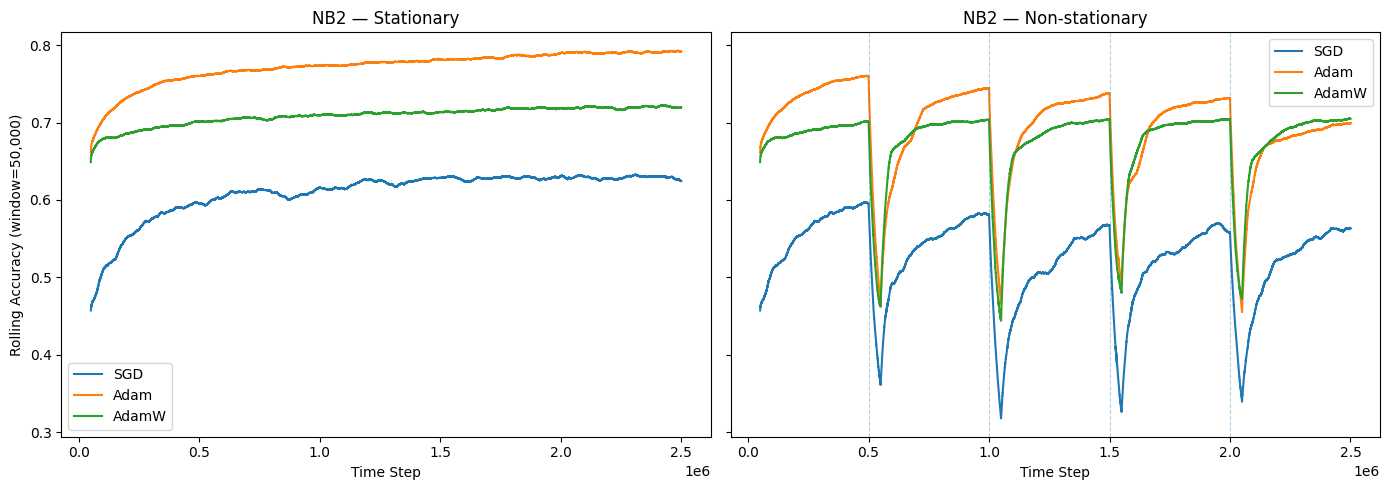

In [17]:
# ============================================================
# 16A. NB2 rolling accuracy — stationary vs non-stationary
# ============================================================

WINDOW = 50_000

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharey=True
)

for optimizer in ["SGD", "Adam", "AdamW"]:
    result = RESULTS[("NB2", optimizer, "stationary")]
    roll = rolling_mean(result["mean_reward"], WINDOW)

    axes[0].plot(
        np.arange(WINDOW, T + 1),
        roll,
        label=optimizer
    )

axes[0].set_title("NB2 — Stationary")
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel(f"Rolling Accuracy (window={WINDOW:,})")
axes[0].legend()

for optimizer in ["SGD", "Adam", "AdamW"]:
    result = RESULTS[("NB2", optimizer, "nonstationary")]
    roll = rolling_mean(result["mean_reward"], WINDOW)

    axes[1].plot(
        np.arange(WINDOW, T + 1),
        roll,
        label=optimizer
    )

for drift in range(DRIFT_INTERVAL, T, DRIFT_INTERVAL):
    axes[1].axvline(
        drift,
        linestyle="--",
        linewidth=0.8,
        alpha=0.35
    )

axes[1].set_title("NB2 — Non-stationary")
axes[1].set_xlabel("Time Step")
axes[1].legend()

plt.tight_layout()
plt.show()


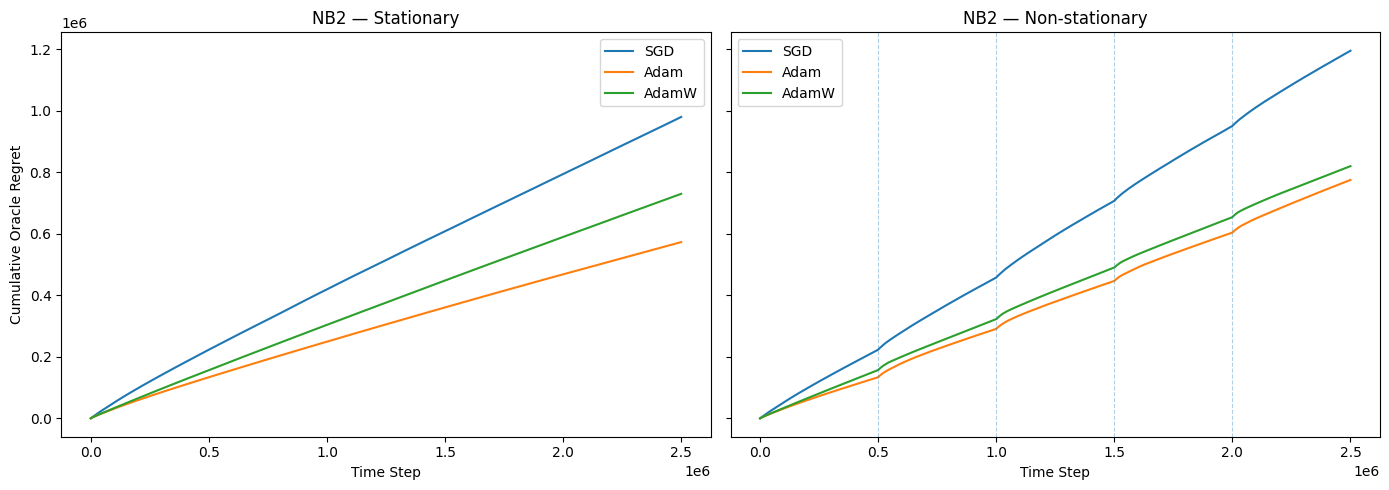

In [18]:
# ============================================================
# 16B. NB2 cumulative oracle regret
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharey=True
)

steps = np.arange(1, T + 1)

for optimizer in ["SGD", "Adam", "AdamW"]:
    axes[0].plot(
        steps,
        RESULTS[("NB2", optimizer, "stationary")]["oracle_regret"],
        label=optimizer
    )

axes[0].set_title("NB2 — Stationary")
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Cumulative Oracle Regret")
axes[0].legend()

for optimizer in ["SGD", "Adam", "AdamW"]:
    axes[1].plot(
        steps,
        RESULTS[("NB2", optimizer, "nonstationary")]["oracle_regret"],
        label=optimizer
    )

for drift in range(DRIFT_INTERVAL, T, DRIFT_INTERVAL):
    axes[1].axvline(
        drift,
        linestyle="--",
        linewidth=0.8,
        alpha=0.35
    )

axes[1].set_title("NB2 — Non-stationary")
axes[1].set_xlabel("Time Step")
axes[1].legend()

plt.tight_layout()
plt.show()


## 17. Secondary NB3 plots

/tmp/ipykernel_2700/2346280653.py:52: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


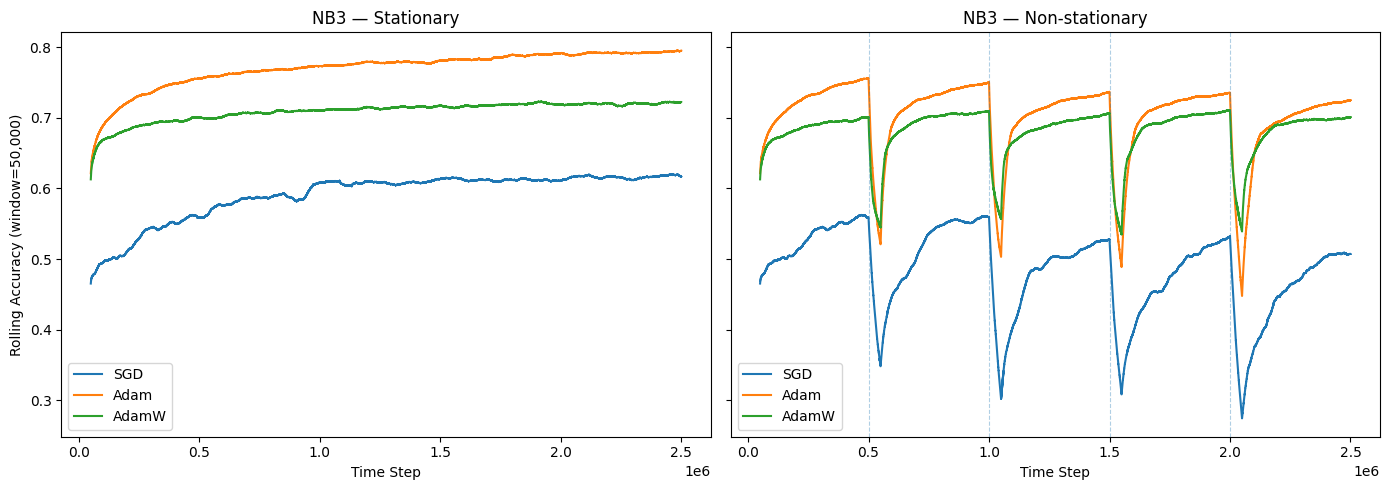

In [19]:
# ============================================================
# 17. NB3 rolling accuracy and regret (if enabled)
# ============================================================

if RUN_NB3_EXTENSION:
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5),
        sharey=True
    )

    for optimizer in ["SGD", "Adam", "AdamW"]:
        roll = rolling_mean(
            RESULTS[("NB3", optimizer, "stationary")]["mean_reward"],
            WINDOW
        )
        axes[0].plot(
            np.arange(WINDOW, T + 1),
            roll,
            label=optimizer
        )

    axes[0].set_title("NB3 — Stationary")
    axes[0].set_xlabel("Time Step")
    axes[0].set_ylabel(f"Rolling Accuracy (window={WINDOW:,})")
    axes[0].legend()

    for optimizer in ["SGD", "Adam", "AdamW"]:
        roll = rolling_mean(
            RESULTS[("NB3", optimizer, "nonstationary")]["mean_reward"],
            WINDOW
        )
        axes[1].plot(
            np.arange(WINDOW, T + 1),
            roll,
            label=optimizer
        )

    for drift in range(DRIFT_INTERVAL, T, DRIFT_INTERVAL):
        axes[1].axvline(
            drift,
            linestyle="--",
            linewidth=0.8,
            alpha=0.35
        )

    axes[1].set_title("NB3 — Non-stationary")
    axes[1].set_xlabel("Time Step")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


## 18. EXP3 learning-rate preference

Because EXP3 selects among hidden-size / learning-rate configurations, its final probabilities give a useful diagnostic of optimizer sensitivity. We aggregate final model-selection probability by learning rate.

For NB3, probabilities are averaged over runs and the seven action-specific EXP3 selectors.


In [20]:
# ============================================================
# 18. Final EXP3 probability by learning rate
# ============================================================


def lr_preference_table(algorithm, optimizer, environment="stationary"):
    result = RESULTS[(algorithm, optimizer, environment)]
    probs = result["final_model_probabilities"]

    if algorithm == "NB2":
        # [runs, models]
        avg_model_prob = probs.mean(axis=0)
    else:
        # [runs, actions, models]
        avg_model_prob = probs.mean(axis=(0, 1))

    lrs = model_lr_vector(optimizer)

    df = pd.DataFrame({
        "learning_rate": lrs,
        "model_probability": avg_model_prob
    })

    return (
        df.groupby("learning_rate", as_index=False)["model_probability"]
        .sum()
        .sort_values("learning_rate")
        .reset_index(drop=True)
    )


for optimizer in ["SGD", "Adam", "AdamW"]:
    print(f"\nNB2 — {optimizer}")
    display(lr_preference_table("NB2", optimizer))



NB2 — SGD


,learning_rate,model_probability
0,0.01,0.933333
1,0.10,0.033333
2,1.00,0.033333



NB2 — Adam


,learning_rate,model_probability
0,0.0001,0.033333
1,0.0010,0.033333
2,0.0100,0.933333



NB2 — AdamW


,learning_rate,model_probability
0,0.0001,0.033333
1,0.0010,0.933333
2,0.0100,0.033333


## 19. Save metadata for reproducibility

In [21]:
# ============================================================
# 19. Save metadata for reproducibility
# ============================================================

metadata = {
    "project": "Adaptive Optimization NeuralBandit",
    "baseline_paper": (
        "A Neural Networks Committee for the Contextual Bandit Problem"
    ),
    "T": T,
    "T_source": "approximately inferred from original Figure 1",
    "n_runs": N_RUNS,
    "gamma": float(GAMMA),
    "gamma_model": float(GAMMA_MODEL),
    "drift_interval": DRIFT_INTERVAL,
    "last_n": LAST_N,
    "hidden_sizes": HIDDEN_SIZES.tolist(),
    "optimizer_configs": {
        name: {
            "code": int(cfg["code"]),
            "learning_rates": cfg["learning_rates"].tolist(),
            "weight_decay": float(cfg["weight_decay"]),
        }
        for name, cfg in OPTIMIZER_CONFIGS.items()
    },
    "adam_beta1": float(ADAM_BETA1),
    "adam_beta2": float(ADAM_BETA2),
    "adam_eps": float(ADAM_EPS),
    "run_starts": RUN_STARTS.tolist(),
    "run_seeds": RUN_SEEDS.tolist(),
    "data_seed": DATA_SEED,
    "experiment_seed": EXPERIMENT_SEED,
    "jax_version": jax.__version__,
    "devices": [str(d) for d in jax.devices()],
    "recovery_metric": {
        "pre_window": RECOVERY_PRE_WINDOW,
        "rolling_window": RECOVERY_ROLLING_WINDOW,
        "threshold_fraction": RECOVERY_FRACTION,
    },
    "design_note": (
        "SGD retains the paper learning-rate grid. Adam and AdamW use "
        "the same adaptive-optimizer grid [1e-4, 1e-3, 1e-2]."
    ),
}

with open(RESULT_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved:", RESULT_DIR / "metadata.json")


Saved: /content/adamw_neural_bandit_results/metadata.json


## 20. Ablation interpretation guide

- **SGD vs Adam**: effect of adaptive first/second moments.
- **Adam vs AdamW**: effect of decoupled weight decay while keeping the adaptive optimizer and learning-rate grid fixed.
- **SGD vs AdamW**: overall proposed-method comparison.
